<a href="https://colab.research.google.com/github/AndrasBajnokSzabo/kaggle-petfinder-adoption-prediction/blob/main/notebooks/data_transformation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files

# This will prompt you to select a file. Choose the kaggle.json you downloaded.
files.upload()

# Set up the Kaggle directory and permissions
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Download and unzip the PetFinder dataset
!kaggle competitions download -c petfinder-adoption-prediction
!unzip -q petfinder-adoption-prediction.zip

Saving kaggle.json to kaggle.json
100% 1.94G/1.94G [00:25<00:00, 82.1MB/s]



In [2]:
import pandas as pd
import numpy as np
import json
import os
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.model_selection import StratifiedKFold
import warnings
warnings.filterwarnings('ignore')

# Adatok beolvasása
train_df = pd.read_csv('train/train.csv')
print(f"Tanító halmaz mérete: {train_df.shape}")

Tanító halmaz mérete: (14993, 24)


# Táblázatos adatok feldolgozása

In [3]:
def process_tabular_features(df):
    # 1. Logaritmikus transzformációk (erősen ferde eloszlásokhoz)
    df['Age_Log'] = np.log1p(df['Age'])
    df['Fee_Log'] = np.log1p(df['Fee'])

    # 2. Bináris indikátorok
    df['Is_Free'] = (df['Fee'] == 0).astype(int)
    df['Has_Name'] = df['Name'].notna().astype(int)

    # 3. Keverék fajta azonosítása (Breed2 kitöltve VAGY Breed1 == 307/Mixed)
    df['Is_Mixed'] = ((df['Breed2'] > 0) | (df['Breed1'] == 307)).astype(int)

    # 4. Egészségügyi és orvosi állapot (1=Yes, 2=No, 3=Not sure)
    # Az oltott, féregtelenített, ivartalanított állapotokat 1-re húzzuk, ha 'Yes'
    df['Medical_Score'] = (
        (df['Vaccinated'] == 1).astype(int) +
        (df['Dewormed'] == 1).astype(int) +
        (df['Sterilized'] == 1).astype(int)
    )

    # 5. Csoportos jellemzők
    df['Is_Group'] = (df['Quantity'] > 1).astype(int)
    df['Fee_Per_Pet'] = df['Fee'] / df['Quantity']

    return df

train_df = process_tabular_features(train_df)
train_df

,Type,Name,Age,Breed1,Breed2,Gender,Color1,Color2,Color3,MaturitySize,...,PhotoAmt,AdoptionSpeed,Age_Log,Fee_Log,Is_Free,Has_Name,Is_Mixed,Medical_Score,Is_Group,Fee_Per_Pet
0,2,Nibble,3,299,0,1,1,7,0,1,...,1.0,2,1.386294,4.615121,0,1,0,0,0,100.0
1,2,No Name Yet,1,265,0,1,1,2,0,2,...,2.0,0,0.693147,0.000000,1,1,0,0,0,0.0
2,1,Brisco,1,307,0,1,2,7,0,2,...,7.0,3,0.693147,0.000000,1,1,1,2,0,0.0
3,1,Miko,4,307,0,2,1,2,0,2,...,8.0,2,1.609438,5.017280,0,1,1,2,0,150.0
4,1,Hunter,1,307,0,1,1,0,0,2,...,3.0,2,0.693147,0.000000,1,1,1,0,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14988,2,NaN,2,266,0,3,1,0,0,2,...,3.0,2,1.098612,0.000000,1,0,0,0,1,0.0
14989,2,Serato & Eddie,60,265,264,3,1,4,7,2,...,3.0,4,4.110874,0.000000,1,1,1,3,1,0.0
14990,2,Monkies,2,265,266,3,5,6,7,3,...,5.0,3,1.098612,3.433987,0,1,1,1,1,6.0
14991,2,Ms Daym,9,266,0,2,4,7,0,1,...,3.0,4,2.302585,0.000000,1,1,0,3,0,0.0


# Leírások kiértékelése

In [4]:
def process_text_features(df):
    # Alapvető statisztikák a szövegről
    df['Description'] = df['Description'].fillna('')
    df['Desc_Length'] = df['Description'].apply(len)
    df['Desc_Word_Count'] = df['Description'].apply(lambda x: len(x.split()))

    # TF-IDF + SVD a szemantikai tartalom kinyerésére (LSA)
    tfidf = TfidfVectorizer(max_features=5000, stop_words='english')
    tfidf_features = tfidf.fit_transform(df['Description'])

    svd = TruncatedSVD(n_components=10, random_state=42)
    svd_features = svd.fit_transform(tfidf_features)

    # SVD komponensek hozzáadása a dataframe-hez
    for i in range(10):
        df[f'Desc_SVD_{i}'] = svd_features[:, i]

    return df

train_df = process_text_features(train_df)
train_df

,Type,Name,Age,Breed1,Breed2,Gender,Color1,Color2,Color3,MaturitySize,...,Desc_SVD_0,Desc_SVD_1,Desc_SVD_2,Desc_SVD_3,Desc_SVD_4,Desc_SVD_5,Desc_SVD_6,Desc_SVD_7,Desc_SVD_8,Desc_SVD_9
0,2,Nibble,3,299,0,1,1,7,0,1,...,0.148500,-0.063485,-0.086104,-0.025119,-0.018412,0.013522,0.031128,-0.053901,0.031479,0.024243
1,2,No Name Yet,1,265,0,1,1,2,0,2,...,0.105796,-0.053528,-0.020325,0.020429,-0.071690,0.016200,0.048235,0.016429,0.006954,0.037458
2,1,Brisco,1,307,0,1,2,7,0,2,...,0.204635,-0.097578,0.076290,0.025872,0.011065,0.111043,-0.097200,-0.026240,-0.238247,0.038503
3,1,Miko,4,307,0,2,1,2,0,2,...,0.170275,-0.049513,-0.028687,0.172242,0.038774,-0.054335,-0.058188,-0.025341,-0.049896,0.017258
4,1,Hunter,1,307,0,1,1,0,0,2,...,0.254278,-0.012976,-0.006918,-0.006112,0.100755,0.028671,0.133753,0.149366,-0.009853,0.146579
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14988,2,NaN,2,266,0,3,1,0,0,2,...,0.255356,-0.095644,-0.081079,-0.187190,-0.078761,0.066233,-0.018063,0.109841,-0.142056,-0.241623
14989,2,Serato & Eddie,60,265,264,3,1,4,7,2,...,0.201749,-0.063188,-0.130014,-0.127599,-0.097778,-0.003087,-0.007070,0.032039,0.025565,-0.158127
14990,2,Monkies,2,265,266,3,5,6,7,3,...,0.161250,-0.056173,-0.115799,0.036325,-0.002974,-0.036775,-0.004844,0.037306,0.036578,-0.113387
14991,2,Ms Daym,9,266,0,2,4,7,0,1,...,0.054733,-0.026317,-0.039851,0.006896,-0.017407,-0.031802,0.047350,-0.014591,0.029080,0.024195


# Sentiment adat betöltése

In [5]:
def load_sentiment_features(df, dataset_type='train'):
    sentiment_dir = f'{dataset_type}_sentiment'
    sentiment_scores = []
    sentiment_magnitudes = []

    for pet_id in df['PetID']:
        file_path = f"{sentiment_dir}/{pet_id}.json"
        if os.path.exists(file_path):
            with open(file_path, 'r', encoding='utf-8') as f:
                data = json.load(f)
                score = data['documentSentiment']['score']
                magnitude = data['documentSentiment']['magnitude']
        else:
            score, magnitude = 0.0, 0.0 # Ha nincs JSON, 0-val töltjük fel

        sentiment_scores.append(score)
        sentiment_magnitudes.append(magnitude)

    df['Sentiment_Score'] = sentiment_scores
    df['Sentiment_Magnitude'] = sentiment_magnitudes
    return df

train_df = load_sentiment_features(train_df, dataset_type='train')
train_df

,Type,Name,Age,Breed1,Breed2,Gender,Color1,Color2,Color3,MaturitySize,...,Desc_SVD_2,Desc_SVD_3,Desc_SVD_4,Desc_SVD_5,Desc_SVD_6,Desc_SVD_7,Desc_SVD_8,Desc_SVD_9,Sentiment_Score,Sentiment_Magnitude
0,2,Nibble,3,299,0,1,1,7,0,1,...,-0.086104,-0.025119,-0.018412,0.013522,0.031128,-0.053901,0.031479,0.024243,0.3,2.4
1,2,No Name Yet,1,265,0,1,1,2,0,2,...,-0.020325,0.020429,-0.071690,0.016200,0.048235,0.016429,0.006954,0.037458,-0.2,0.7
2,1,Brisco,1,307,0,1,2,7,0,2,...,0.076290,0.025872,0.011065,0.111043,-0.097200,-0.026240,-0.238247,0.038503,0.2,3.7
3,1,Miko,4,307,0,2,1,2,0,2,...,-0.028687,0.172242,0.038774,-0.054335,-0.058188,-0.025341,-0.049896,0.017258,0.9,0.9
4,1,Hunter,1,307,0,1,1,0,0,2,...,-0.006918,-0.006112,0.100755,0.028671,0.133753,0.149366,-0.009853,0.146579,0.6,3.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14988,2,NaN,2,266,0,3,1,0,0,2,...,-0.081079,-0.187190,-0.078761,0.066233,-0.018063,0.109841,-0.142056,-0.241623,0.4,2.5
14989,2,Serato & Eddie,60,265,264,3,1,4,7,2,...,-0.130014,-0.127599,-0.097778,-0.003087,-0.007070,0.032039,0.025565,-0.158127,0.0,0.3
14990,2,Monkies,2,265,266,3,5,6,7,3,...,-0.115799,0.036325,-0.002974,-0.036775,-0.004844,0.037306,0.036578,-0.113387,0.8,2.5
14991,2,Ms Daym,9,266,0,2,4,7,0,1,...,-0.039851,0.006896,-0.017407,-0.031802,0.047350,-0.014591,0.029080,0.024195,0.9,0.9


# K-fold kialakítás

A k-fold-ra azért van szükség, hogy elkerüljük a tultanulast, legyen validacios halmazunk.
Úgy osztjuk fel hogy minden fold-ba kerüljön minden féle cimkebol egyenletesen.

In [6]:
# 5-szörös Stratified K-Fold kialakítása
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
train_df['Fold'] = -1

for fold, (train_idx, val_idx) in enumerate(skf.split(train_df, train_df['AdoptionSpeed'])):
    train_df.loc[val_idx, 'Fold'] = fold

print("Osztályok eloszlása foldonként:")
print(pd.crosstab(train_df['Fold'], train_df['AdoptionSpeed']))

Osztályok eloszlása foldonként:
AdoptionSpeed   0    1    2    3    4
Fold                                 
0              82  618  808  652  839
1              82  618  808  651  840
2              82  618  807  652  840
3              82  618  807  652  839
4              82  618  807  652  839


In [7]:
import os
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
from PIL import Image
import numpy as np
import pandas as pd
from sklearn.decomposition import TruncatedSVD
from tqdm import tqdm # Folyamatjelzőhöz

# 1. Eszköz beállítása (GPU használata, ha elérhető a Colab-ban)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Használt eszköz: {device}")

# 2. Előre betanított ResNet50 betöltése (ImageNet súlyokkal)
# A 'weights=DEFAULT' az ajánlott szintaxis az új PyTorch verziókban
model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
# Levágjuk az utolsó osztályozó réteget, hogy csak a 2048-dimenziós jellemzővektort kapjuk
model.fc = nn.Identity()
model = model.to(device)
model.eval() # Értékelő (inferencia) mód bekapcsolása

# 3. Képtranszformációs pipeline (a ResNet50 elvárt bemenete)
transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

def extract_image_embeddings(df, image_dir='train_images'):
    embeddings = []

    # Végigmegyünk az összes PetID-n
    for pet_id in tqdm(df['PetID'], desc="Képek feldolgozása"):
        # A versenyben a profilkép mindig a PetID-1.jpg
        img_path = os.path.join(image_dir, f"{pet_id}-1.jpg")

        if os.path.exists(img_path):
            try:
                # Kép beolvasása és RGB-re konvertálása
                img = Image.open(img_path).convert('RGB')
                img_t = transform(img).unsqueeze(0).to(device) # Batch dimenzió hozzáadása

                # Gradiens számítás kikapcsolása a gyorsítás és memóriamegtakarítás érdekében
                with torch.no_grad():
                    emb = model(img_t).cpu().numpy().flatten()
                embeddings.append(emb)
            except Exception as e:
                # Ha a kép sérült, csupa nullával töltjük fel
                embeddings.append(np.zeros(2048))
        else:
            # Ha egyáltalán nincs profilkép
            embeddings.append(np.zeros(2048))

    return np.array(embeddings)

# 4. Kinyerjük a 2048-dimenziós vektorokat
# Feltételezzük, hogy a képek a 'train_images' mappában vannak
print("Embeddingek generálása...")
raw_embeddings = extract_image_embeddings(train_df, image_dir='train_images')

# 5. Dimenziócsökkentés: 2048 oszlop túl sok lenne, 15 komponensre sűrítjük (SVD)
print("Dimenziócsökkentés SVD-vel (2048 -> 15)...")
n_components = 15
svd = TruncatedSVD(n_components=n_components, random_state=42)
reduced_embeddings = svd.fit_transform(raw_embeddings)

# 6. Az új jellemzők hozzáfűzése a meglévő DataFrame-hez
for i in range(n_components):
    train_df[f'Img_Embed_{i}'] = reduced_embeddings[:, i]

print("A kép-embedding jellemzők sikeresen hozzáadva a train_df-hez!")

Használt eszköz: cuda
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 173MB/s]


Embeddingek generálása...


Képek feldolgozása: 100%|██████████| 14993/14993 [02:38<00:00, 94.50it/s]


Dimenziócsökkentés SVD-vel (2048 -> 15)...
A kép-embedding jellemzők sikeresen hozzáadva a train_df-hez!


# Fontos jellemzők kiválasztása az aadthalmazból

LightGBM illetve SHAP használata arra, hogy a modell által használt legfontosabnnak ítélt jellemzőket kiválasszuk.

Training until validation scores don't improve for 20 rounds
Did not meet early stopping. Best iteration is:
[200]	valid_0's multi_logloss: 1.37256

SHAP értékek kiszámítása...


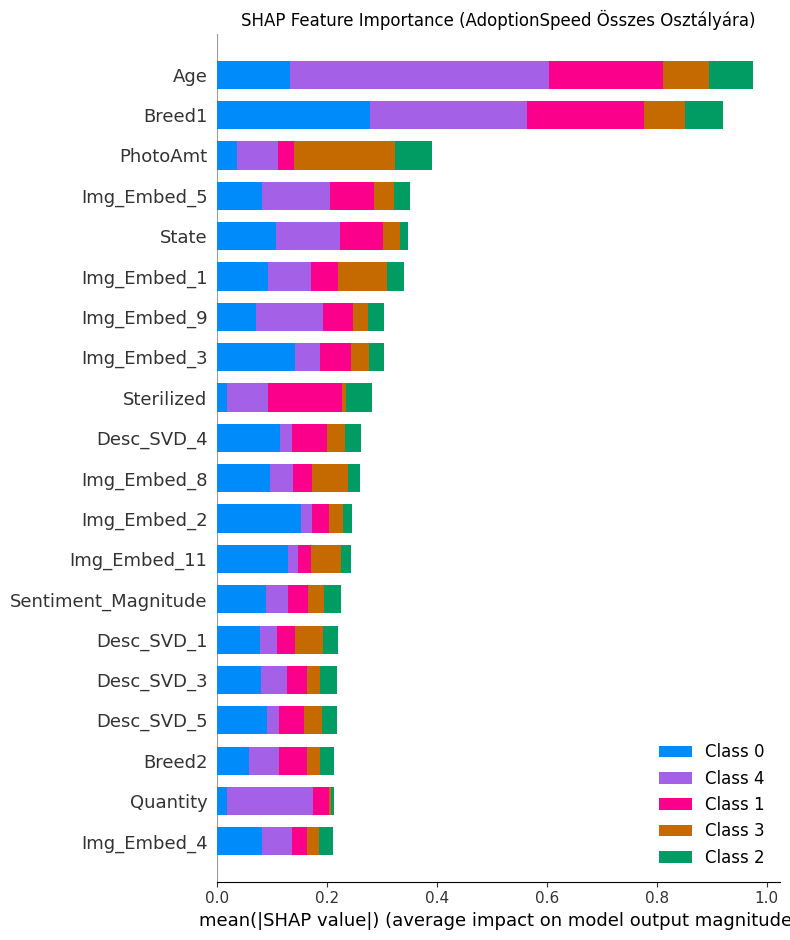

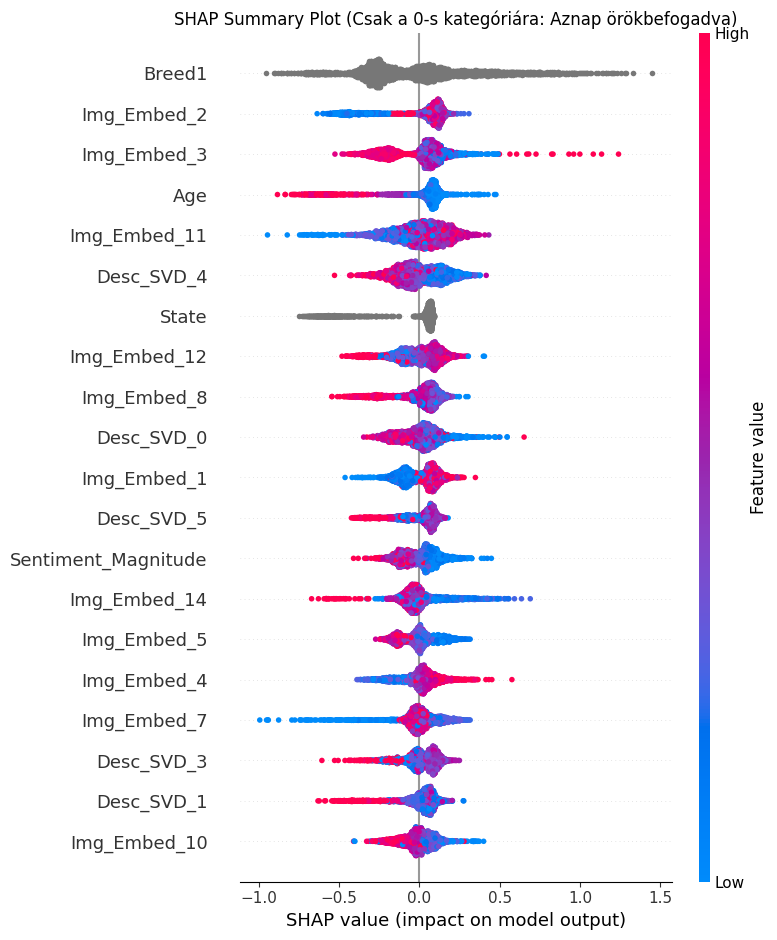

In [8]:
import lightgbm as lgb
import shap
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Adatok előkészítése a modell számára
# Feltételezzük, hogy a 'train_df' már tartalmazza az összes új feature-t.
# Kiválasztjuk a bemeneti oszlopokat (X) és a célváltozót (y)
features_to_drop = ['PetID', 'Name', 'RescuerID', 'Description', 'AdoptionSpeed', 'Fold']
features = [col for col in train_df.columns if col not in features_to_drop]

X = train_df[features]
y = train_df['AdoptionSpeed']

# 2. LightGBM kategória oszlopainak definiálása
categorical_features = ['Type', 'Breed1', 'Breed2', 'Gender', 'Color1', 'Color2', 'Color3',
                        'State', 'MaturitySize', 'FurLength', 'Health']

# Biztosítjuk, hogy a kategóriák 'category' típusúak legyenek a Pandas-ban
for col in categorical_features:
    if col in X.columns:
        X[col] = X[col].astype('category')

# 3. LightGBM modell betanítása (egyszerű hold-out validációval a gyors SHAP számításhoz)
from sklearn.model_selection import train_test_split
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 1. LightGBM paraméterek kiegészítése a 'verbose': -1 értékkel a csendes futáshoz
lgb_params = {
    'objective': 'multiclass',
    'num_class': 5,
    'metric': 'multi_logloss',
    'learning_rate': 0.05,
    'max_depth': 6,
    'num_leaves': 31,
    'class_weight': 'balanced',
    'random_state': 42,
    'n_estimators': 200,
    'verbose': -1  # <--- EZ KIKAPCSOLJA A ZAVARÓ WARNINGOKAT
}

model = lgb.LGBMClassifier(**lgb_params)
model.fit(
    X_train, y_train,
    eval_set=[(X_valid, y_valid)],
    categorical_feature=categorical_features,
    callbacks=[lgb.early_stopping(stopping_rounds=20)]
)

print("\nSHAP értékek kiszámítása...")
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_valid)

# 2. Globális Fontosság Plot
plt.figure(figsize=(10, 8))
plt.title("SHAP Feature Importance (AdoptionSpeed Összes Osztályára)")
shap.summary_plot(shap_values, X_valid, plot_type="bar", show=False)
plt.tight_layout()
plt.show()

# 3. A 0-s osztály kinyerése a mátrix formátumától függően (javított rész)
if isinstance(shap_values, list):
    # Ha régebbi SHAP verziód van (lista)
    shap_values_0 = shap_values[0]
else:
    # Ha újabb SHAP verziód van (3D NumPy array: [sorok, jellemzők, osztályok])
    shap_values_0 = shap_values[:, :, 0]

# 4. Részletes Plot a 0-s osztályra
plt.figure(figsize=(10, 8))
plt.title("SHAP Summary Plot (Csak a 0-s kategóriára: Aznap örökbefogadva)")
shap.summary_plot(shap_values_0, X_valid, show=False)
plt.tight_layout()
plt.show()

## 6. Végső Jellemzőtér Kialakítása (Feature Selection)

A korábbi lépésekben több tucat új jellemzőt hoztunk létre (TF-IDF SVD komponensek, ResNet50 kép-embeddingek, stb.). Annak érdekében, hogy elkerüljük a túlilleszkedést (overfitting) és a dimenzionalitás átkát, a LightGBM modellünk SHAP analízisét használtuk a jellemzők szűrésére.

**Kiválasztási stratégia:**
1. **Alapjellemzők:** Megtartottuk a legerősebb prediktorokat (Age, Breed1, PhotoAmt), amelyek a globális fontossági listát vezetik.
2. **Képi jellemzők (Embeddings):** A SHAP ábrák alapján a ResNet50 által kinyert vizuális jellemzők (`Img_Embed`) rendkívül erős hatással bírnak az osztályozásra (különösen az azonnali örökbefogadásra), így a legmagasabb SHAP értékűeket beválogattuk.
3. **Szöveg és Metaadat:** A leírások szemantikai tartalmát sűrítő SVD komponensek közül csak a legjobban teljesítőket tartottuk meg, kiegészítve a Google Natural Language API `Sentiment_Magnitude` értékével.

Az alábbi kód létrehozza a megtisztított, végső adathalmazt, amely már készen áll a 3. mérföldkő (modellezés) számára.

In [9]:
import pandas as pd

# 1. A SHAP ábrák alapján kiválasztott legfontosabb jellemzők listája
selected_features = [
    # Alapjellemzők
    'Age', 'Breed1', 'Breed2', 'PhotoAmt', 'State', 'Quantity',
    # Kategóriás / Bináris jellemzők
    'Sterilized',
    # Érzelmi elemzés
    'Sentiment_Magnitude',
    # A legjobban teljesítő Szöveges (SVD) jellemzők
    'Desc_SVD_4', 'Desc_SVD_1', 'Desc_SVD_3', 'Desc_SVD_5', 'Desc_SVD_0',
    # A legjobban teljesítő Kép (Embedding) jellemzők
    'Img_Embed_5', 'Img_Embed_1', 'Img_Embed_9', 'Img_Embed_3',
    'Img_Embed_8', 'Img_Embed_2', 'Img_Embed_11', 'Img_Embed_4'
]

# 2. A végső tanító és célváltozó adathalmaz létrehozása
X_final = train_df[selected_features].copy()
y_final = train_df['AdoptionSpeed'].copy()

print(f"Végső jellemzőtér mérete: {X_final.shape}")
# Ezt érdemes elmenteni a következő mérföldkőhöz
# X_final.to_csv("train_features_selected.csv", index=False)
train_df.head()

Végső jellemzőtér mérete: (14993, 21)


,Type,Name,Age,Breed1,Breed2,Gender,Color1,Color2,Color3,MaturitySize,...,Img_Embed_5,Img_Embed_6,Img_Embed_7,Img_Embed_8,Img_Embed_9,Img_Embed_10,Img_Embed_11,Img_Embed_12,Img_Embed_13,Img_Embed_14
0,2,Nibble,3,299,0,1,1,7,0,1,...,1.033997,-0.749386,-2.894050,1.684926,0.492929,0.133612,-0.155790,-0.382821,-0.186248,0.262895
1,2,No Name Yet,1,265,0,1,1,2,0,2,...,-0.671333,-2.930829,-1.305215,-0.182357,-0.773658,1.531793,-1.444664,0.664881,-1.650277,-1.700389
2,1,Brisco,1,307,0,1,2,7,0,2,...,-0.891835,-0.190969,2.018304,-0.226139,-0.130527,0.459133,2.055497,0.917964,-2.661553,-0.318270
3,1,Miko,4,307,0,2,1,2,0,2,...,-0.163184,-1.123392,2.566063,-2.655610,2.101184,-2.659890,2.349023,-0.065692,0.477716,-1.093135
4,1,Hunter,1,307,0,1,1,0,0,2,...,-1.264614,-0.282885,-2.034858,2.530058,2.875551,-0.106784,-0.434196,0.558406,-1.110262,-0.659016


In [10]:
import os
from sklearn.model_selection import train_test_split

# Hozzuk létre a mentési könyvtárat
os.makedirs('processed_data', exist_ok=True)

# Teszthalmaz leválasztása (20%) - Ezt a modell sosem látja
X_temp, X_test, y_temp, y_test = train_test_split(
    X_final, y_final, test_size=0.20, random_state=42, stratify=y_final
)

# A maradék (80%) felosztása Tanító (Train  ~75%) és Validációs (Val ~25%) halmazra
# A teljes adathalmazra nézve így ~60% Train, 20% Val, 20% Test arányt kapunk.
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp
)

print(f"Teljes adatbázis mérete: {X_final.shape[0]}")
print(f"Tanító (Train) halmaz: {X_train_final.shape[0]} sor ({(X_train_final.shape[0]/X_final.shape[0])*100:.1f}%)")
print(f"Validációs (Val) halmaz: {X_val.shape[0]} sor ({(X_val.shape[0]/X_final.shape[0])*100:.1f}%)")
print(f"Teszt (Test) halmaz: {X_test.shape[0]} sor ({(X_test.shape[0]/X_final.shape[0])*100:.1f}%)")

# Reprodukálhatóság biztosítása: adathalmazok mentése
X_train_final.assign(AdoptionSpeed=y_train_final).to_csv('processed_data/train_split.csv', index=False)
X_val.assign(AdoptionSpeed=y_val).to_csv('processed_data/val_split.csv', index=False)
X_test.assign(AdoptionSpeed=y_test).to_csv('processed_data/test_split.csv', index=False)

print("\nAz adathalmazok sikeresen szétválasztva és kimentve a 'processed_data' mappába.")

Teljes adatbázis mérete: 14993
Tanító (Train) halmaz: 8995 sor (60.0%)
Validációs (Val) halmaz: 2999 sor (20.0%)
Teszt (Test) halmaz: 2999 sor (20.0%)

Az adathalmazok sikeresen szétválasztva és kimentve a 'processed_data' mappába.


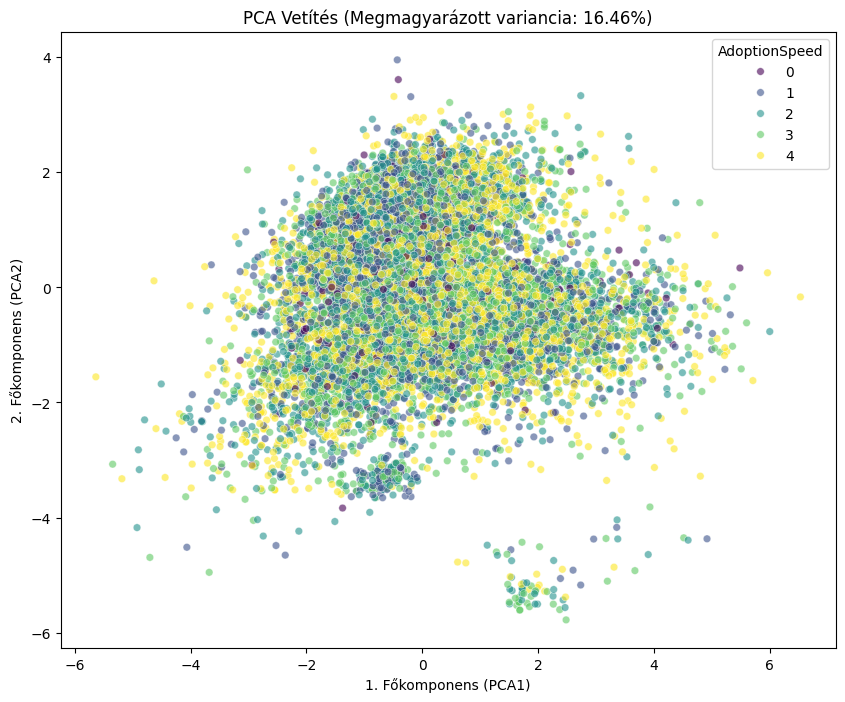

t-SNE vetítés számítása folyamatban... (ez eltarthat 1-2 percig)


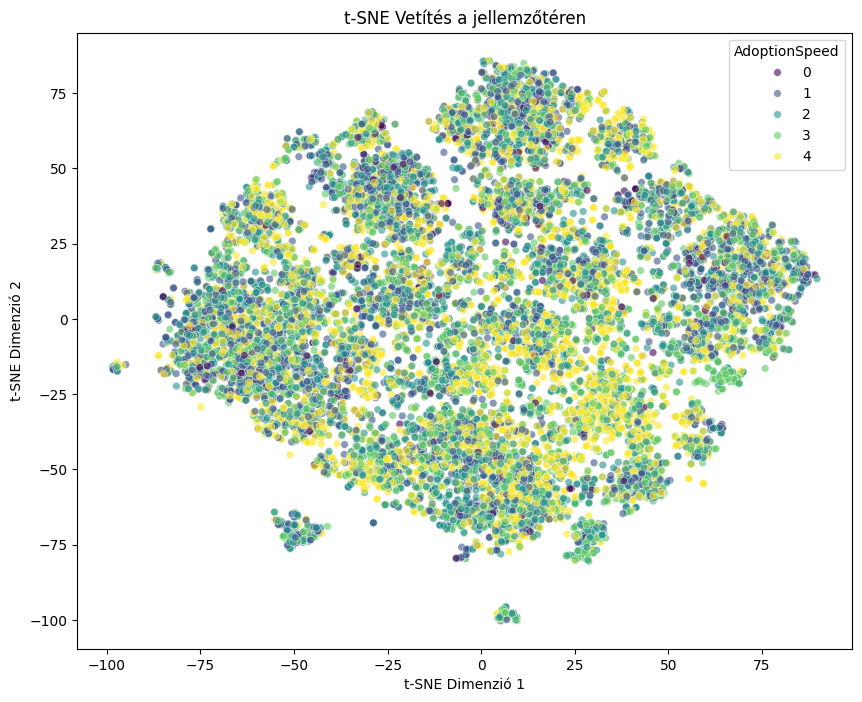


A vizualizációk sikeresen lementve a 'visualizations' mappába.


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

# Könyvtár a vizualizációk mentéséhez
os.makedirs('visualizations', exist_ok=True)

# Adatok standardizálása (távolság alapú algoritmusokhoz elengedhetetlen)
# Fontos: A szivárgás elkerülése végett a scalert csak a Train adatokon illesztjük, de a teljes X_final-t transzformáljuk a vizualizációhoz
scaler = StandardScaler()
scaler.fit(X_train_final)
X_scaled = scaler.transform(X_final)

# PCA vetítés (2D) - Főkomponens analízis a lineáris mintázatokhoz
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 8))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_final, palette='viridis', alpha=0.6, s=30)
plt.title(f'PCA Vetítés (Megmagyarázott variancia: {sum(pca.explained_variance_ratio_)*100:.2f}%)')
plt.xlabel('1. Főkomponens (PCA1)')
plt.ylabel('2. Főkomponens (PCA2)')
plt.legend(title='AdoptionSpeed')
plt.savefig('visualizations/pca_projection.png', dpi=300, bbox_inches='tight')
plt.show()

# t-SNE vetítés (2D) - Nem lineáris dimenziócsökkentés a komplexebb klaszterek kereséséhez
print("t-SNE vetítés számítása folyamatban")
tsne = TSNE(n_components=2, random_state=42, n_jobs=-1, perplexity=30)
X_tsne = tsne.fit_transform(X_scaled)

plt.figure(figsize=(10, 8))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=y_final, palette='viridis', alpha=0.6, s=30)
plt.title('t-SNE Vetítés a jellemzőtéren')
plt.xlabel('t-SNE Dimenzió 1')
plt.ylabel('t-SNE Dimenzió 2')
plt.legend(title='AdoptionSpeed')
plt.savefig('visualizations/tsne_projection.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nA vizualizációk sikeresen lementve a 'visualizations' mappába.")